# Actual H49 training: exposure, optimization and pipeline stages

This notebook reads the real two-rank training trace. It never refits a model or
prints private row IDs/text. Logical optimizer updates are shared across DDP ranks;
rows/tokens are summed. Canonical-label counts differ from randomly swapped
training targets. Missing measurements remain missing.


In [1]:
import json,sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
REPO=Path.cwd().resolve()
if not (REPO/'GOAL.md').exists():REPO=REPO.parent
sys.path.insert(0,str(REPO/'src'))
from arena.data import ROOT
PUB=REPO/'results/span_007';RUN=ROOT/'runs/span_007';FIG=RUN/'figures';FIG.mkdir(parents=True,exist_ok=True)
def read(path):return json.loads(Path(path).read_text())
def result(name):
    path=PUB/name
    if name in ['H49_results.json','H48_results.json']:
        recovered=PUB/name.replace('_results.json','_recovered_artifacts_results.json')
        if recovered.exists():path=recovered
    return read(path)
def save(fig,name):
    for suffix in ['png','svg']:fig.savefig(FIG/(name+'.'+suffix),dpi=160,bbox_inches='tight')
    plt.show()
cfg=read(REPO/'configs/span_007.json')

OUT=RUN/'jobs/continuation/output/continuation'
summary=read(OUT/'summary.json');audit=result('training_audit.json');source=read(OUT/'resume_source.json')
events=[json.loads(line) for line in (OUT/'telemetry/events.jsonl').read_text().splitlines()]
metrics=pd.DataFrame([{'step':e['step'],**e['metrics']} for e in events if e['event']=='metrics' and 'loss' in e.get('metrics',{})])
cycles=pd.DataFrame([{'step':e['step'],**e['counts'],**e.get('metrics',{}),**e.get('gpu',{})} for e in events if e['event']=='cycle'])
validation=pd.DataFrame([{'step':e['step'],**e['metrics']} for e in events if e['stage']=='validation' and e['event']=='measured'])
print('Source step:',summary['initial_step'],'final step:',summary['final_step'],'new cycles:',summary['new_cycles'])
print('Budget stop:',summary['stopped_for_budget'],'instability stop:',summary['stopped_for_instability'])
print('Restored state:',{k:v for k,v in source.items() if k!='parent_checkpoint_files'})
print('Audit:',audit)


Source step: 1438 final step: 1694 new cycles: 256
Budget stop: False instability stop: True
Restored state: {'parent_adapter_sha256': 'ca8be9cfd98309fdc8406bf740b13ed3ee413f3820ec6bcbbf7f3f4059f4b15b', 'parent_scheduler_position': 1434, 'parent_amp_scale': 4096.0, 'parent_optimizer_fingerprint': '8ef15c99eecd6ce94c0ab909f7dcbc4869d48e7fdbfad2d3bc5394021651c151', 'restarted_scheduler_origin': 1434, 'first_learning_rates': [6.25e-07, 6.25e-07], 'parent_optimizer_restored': True, 'parent_scaler_restored': True, 'schedule_change': 'Accepted-position warm restart; not unchanged historical schedule'}
Audit: {'passed': True, 'checked_at': '2026-11-05T21:54:13.947343+00:00', 'service_status': 'ERROR', 'complete_artifact_recovery': True, 'new_nominal_cycles': 256, 'new_logical_accepted_updates': 256, 'new_logical_skipped_updates': 0, 'global_accepted_rows': 8192, 'global_accepted_unique_rows': 8192, 'global_accepted_packed_tokens': 4831619, 'per_rank': [{'rank': 0, 'cycles': 256, 'accepted_upd

## Learning curve

Training loss averages recent sampled training orientations with dropout. The
256-row monitoring loss uses original-order development inputs. It is used for
the fixed stopping rule, not selection of a best checkpoint. Full-development
swap-averaged/calibrated loss is a different measurement in the results notebook.


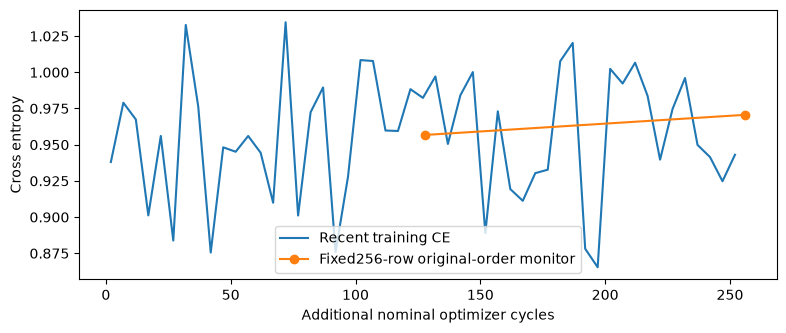

,step,eval_loss,eval_log_loss,eval_accuracy,eval_balanced_accuracy,eval_macro_f1,eval_brier,eval_runtime,eval_samples_per_second,eval_steps_per_second,epoch
0,1566,0.956740,0.956740,0.546875,0.541560,0.535803,0.569722,79.2604,3.230,0.404,1.089059
1,1694,0.970608,0.970608,0.542969,0.545987,0.534879,0.577938,79.3228,3.227,0.403,1.178118


In [2]:
fig,ax=plt.subplots(figsize=(9,3.5));ax.plot(metrics.step-1438,metrics.loss,label='Recent training CE')
if len(validation):ax.plot(validation.step-1438,validation.eval_log_loss,'o-',label='Fixed256-row original-order monitor')
ax.set_xlabel('Additional nominal optimizer cycles');ax.set_ylabel('Cross entropy');ax.legend();save(fig,'training_learning_curve')
display(validation)


## Optimization is measured in accepted updates

The restarted schedule is anchored to the restored accepted scheduler position.
AMP skips do not advance it. Gradient norm is measured before clipping; the clip
threshold is1. A nonfinite observation is represented by a missing value plus
an explicit flag, not a zero. Scaler history remains visible.


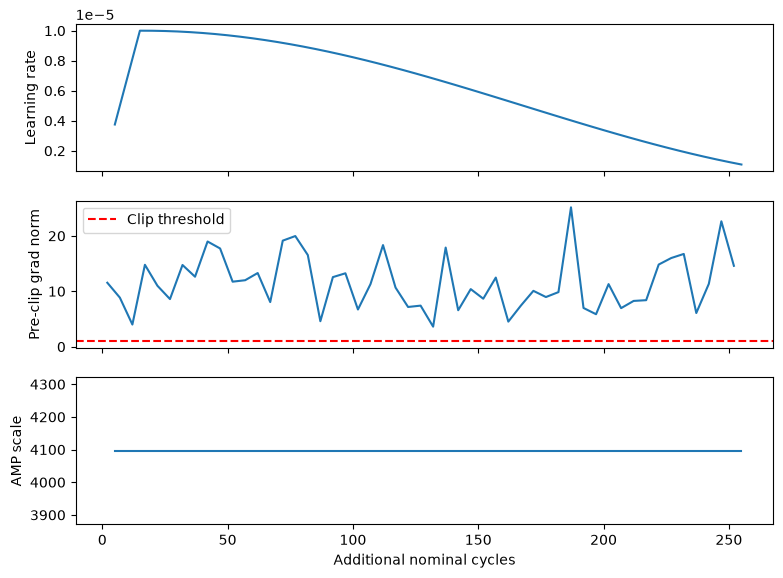

In [3]:
fig,axes=plt.subplots(3,1,figsize=(9,6.5),sharex=True)
axes[0].plot(cycles.step-1438,cycles.learning_rate);axes[0].set_ylabel('Learning rate')
axes[1].plot(metrics.step-1438,metrics.grad_norm);axes[1].axhline(1,color='red',linestyle='--',label='Clip threshold');axes[1].set_ylabel('Pre-clip grad norm');axes[1].legend()
axes[2].step(cycles.step-1438,cycles.amp_scale,where='post');axes[2].set_ylabel('AMP scale');axes[2].set_xlabel('Additional nominal cycles')
save(fig,'training_optimizer')


## Content exposure and hardware

Tokens are real packed content, excluding padding. The audit validates canonical
training labels, held-out exclusion, per-cycle scheduler/scaler behavior and
agreement of DDP skip vectors. Per-rank unique counts cannot be summed into a
global unique count. Peak memory covers this complete run, not an isolated
inference-only measurement. Curves show periodic samples; audited totals below
include the final cycle.


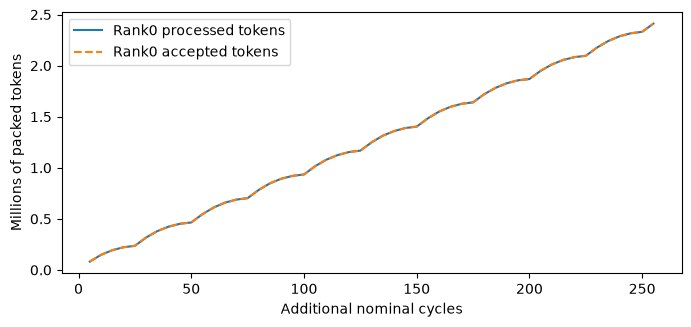

,rank,cycles,accepted_updates,skipped_updates,processed_tokens,accepted_tokens,processed_rows,accepted_rows,processed_unique_rows,accepted_unique_rows,processed_class_counts,accepted_class_counts,last_global_step
0,0,256,256,0,2425592,2425592,4096,4096,4096,4096,"[1443, 1364, 1289]","[1443, 1364, 1289]",1694
1,1,256,256,0,2406027,2406027,4096,4096,4096,4096,"[1497, 1395, 1204]","[1497, 1395, 1204]",1694


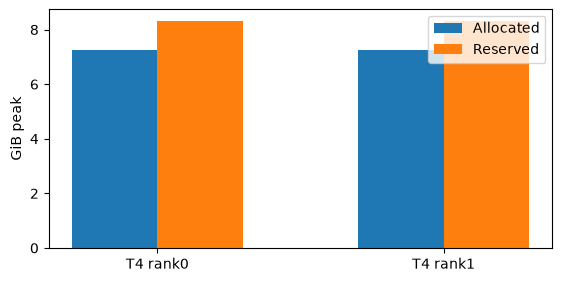

In [4]:
fig,ax=plt.subplots(figsize=(8,3.4));ax.plot(cycles.step-1438,cycles.processed_tokens/1e6,label='Rank0 processed tokens');ax.plot(cycles.step-1438,cycles.accepted_tokens/1e6,'--',label='Rank0 accepted tokens');ax.set_xlabel('Additional nominal cycles');ax.set_ylabel('Millions of packed tokens');ax.legend();save(fig,'training_exposure')
rank_summaries=[read(OUT/f'exposure_summary_rank{i}.json') for i in [0,1]];display(pd.DataFrame(rank_summaries))
hardware=[read(OUT/f'gpu_rank{i}.json') for i in [0,1]];fig,ax=plt.subplots(figsize=(6.5,3.1));x=np.arange(2);ax.bar(x-.15,[r['peak_allocated_bytes']/2**30 for r in hardware],.3,label='Allocated');ax.bar(x+.15,[r['peak_reserved_bytes']/2**30 for r in hardware],.3,label='Reserved');ax.set_xticks(x,['T4 rank0','T4 rank1']);ax.set_ylabel('GiB peak');ax.legend();save(fig,'training_gpu_memory')


## Audit boundaries

The legacy training loader loads CSV columns; only train/dev labels are selected
for training, monitoring and final development. The original worker's unread
flag is interpreted as unused, as documented in the target-access audit. Frozen
source and target-isolation tests support that distinction. H50 freezes a candidate
before its explicit confirmation evaluation. All original evaluation data was
historically inspected. Check the saved audit rather than inferring state from
missing process visibility in a sandbox.


In [5]:
charge=read(PUB/'jobs/continuation/controller_state.json')['charged_seconds']
display(pd.DataFrame([{'stage':'Trainer wall including monitoring/checkpoints','seconds':summary['training_seconds']},
                      {'stage':'Final development prediction','seconds':summary['development_prediction_seconds']},
                      {'stage':'Other charged setup/packing/identity/teardown','seconds':charge-summary['training_seconds']-summary['development_prediction_seconds']}]))
print('Source/fold documentation:',REPO/'docs/SPAN_007_TARGET_ACCESS.md')
print('Parent optimizer fingerprint:',source['parent_optimizer_fingerprint'])
print('Full trace remains private:',OUT)


,stage,seconds
0,Trainer wall including monitoring/checkpoints,5913.436279
1,Final development prediction,3626.891361
2,Other charged setup/packing/identity/teardown,348.618360


Source/fold documentation: /home/tarstars/prj/llm_classification_finetuning/docs/SPAN_007_TARGET_ACCESS.md
Parent optimizer fingerprint: 8ef15c99eecd6ce94c0ab909f7dcbc4869d48e7fdbfad2d3bc5394021651c151
Full trace remains private: /home/tarstars/database/llm_classification_finetuning/runs/span_007/jobs/continuation/output/continuation
